# Diagnostics example

We’ll go through some diagnostics using
[arviz](https://python.arviz.org).

Step one is to load some data. Rather than going through a whole
modelling workflow, we’ll just take one of the example MCMC outputs that
arviz provides via the function
[`load_arviz_data`](https://python.arviz.org/en/stable/api/%20generated/arviz.load_arviz_data.html).

This particular MCMC output has to do with measurements of soil
radioactivity in the USA. You can read more about it
[here](https://docs.pymc.io/notebooks/multilevel_modeling.html).

In [1]:
import arviz as az
import numpy as np
import xarray as xr 

idata = az.load_arviz_data("radon")
idata

Inference data with groups:
	> posterior
	> posterior_predictive
	> log_likelihood
	> sample_stats
	> prior
	> prior_predictive
	> observed_data
	> constant_data

Arviz provides a data structure called
[`InferenceData`](https://%20python.arviz.org/en/latest/api/inference_data.html)
which it uses for storing MCMC outputs. It’s worth getting to know it:
there is some helpful explanation
[here](https://python.arviz.org/en/latest/schema/schema.html).

At a high level, an `InferenceData` is a container for several xarray
`Dataset` objects called ‘groups’. Each group contains xarray
\[`DataArray`\] (https:// docs.xarray.dev/
en/stable/generated/xarray.DataArray.html) objects called ‘variables’.
Each variable contains a rectangular array of values, plus the shape of
the values (‘dimensions’) and labels for the dimensions (‘coordinates’).

For example, if you click on the dropdown arrows above you will see that
the group `posterior` contains a variable called `a_county` that has
three dimensions called `chain`, `draw` and `County`. There are 85
counties and the first one is labelled `'AITKIN'`.

The function
[`az.summary`](https://python.arviz.org/en/latest/api/generated/arviz.summary.html)
lets us look at some useful summary statistics, including $\hat{R}$,
divergent transitions and MCSE.

The variable `lp`, which you can find in the group `sample_stats` is the
model’s total log probability density. It’s not very meaningful on its
own, but is useful for judging overall convergence. `diverging` counts
the number of divergent transitions.

In [2]:
az.summary(idata.sample_stats, var_names=["lp", "diverging"])

/Users/tedgro/repos/dtu-qmcm/bayesian_statistics_for_computational_biology/.venv/lib/python3.13/site-packages/arviz/stats/diagnostics.py:596: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/Users/tedgro/repos/dtu-qmcm/bayesian_statistics_for_computational_biology/.venv/lib/python3.13/site-packages/arviz/stats/diagnostics.py:991: RuntimeWarning: invalid value encountered in scalar divide
  varsd = varvar / evar / 4


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
lp,-1143.808,9.272,-1160.741,-1126.532,0.426,0.242,477.0,772.0,1.01
diverging,0.000,0.000,0.000,0.000,0.000,NaN,2000.0,2000.0,NaN


In [11]:
idata.sample_stats["diverging"].sum().item()

0

In this case there were no post-warmup diverging transitions, and the
$\hat{R}$ statistic for the `lp` variable is pretty close to 1: great!

Sometimes it’s useful to summarise individual parameters. This can be
done by pointing `az.summary` at the group where the parameters of
interest live. In this case the group is called `posterior`.

In [14]:
az.summary(idata.posterior, var_names=["sigma", "g"])

arviz - WARNING - Shape validation failed: input_shape: (1, 500), minimum_shape: (chains=2, draws=4)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
sigma,0.949,0.907,0.001,2.717,0.042,0.056,461.0,445.0,NaN
g[intercept],0.613,10.542,-17.332,20.816,0.522,0.393,411.0,401.0,NaN
g[slope],0.973,10.340,-17.222,19.592,0.461,0.409,504.0,454.0,NaN


Now we can start evaluating the model. First we check to see whether
replicated measurements from the model’s posterior predictive
distribution broadly agree with the observed measurements, using the
arviz function
[`plot_lm`](https://python.arviz.org/en/latest/api/generated/arviz.plot_lm.html#arviz.plot_lm):

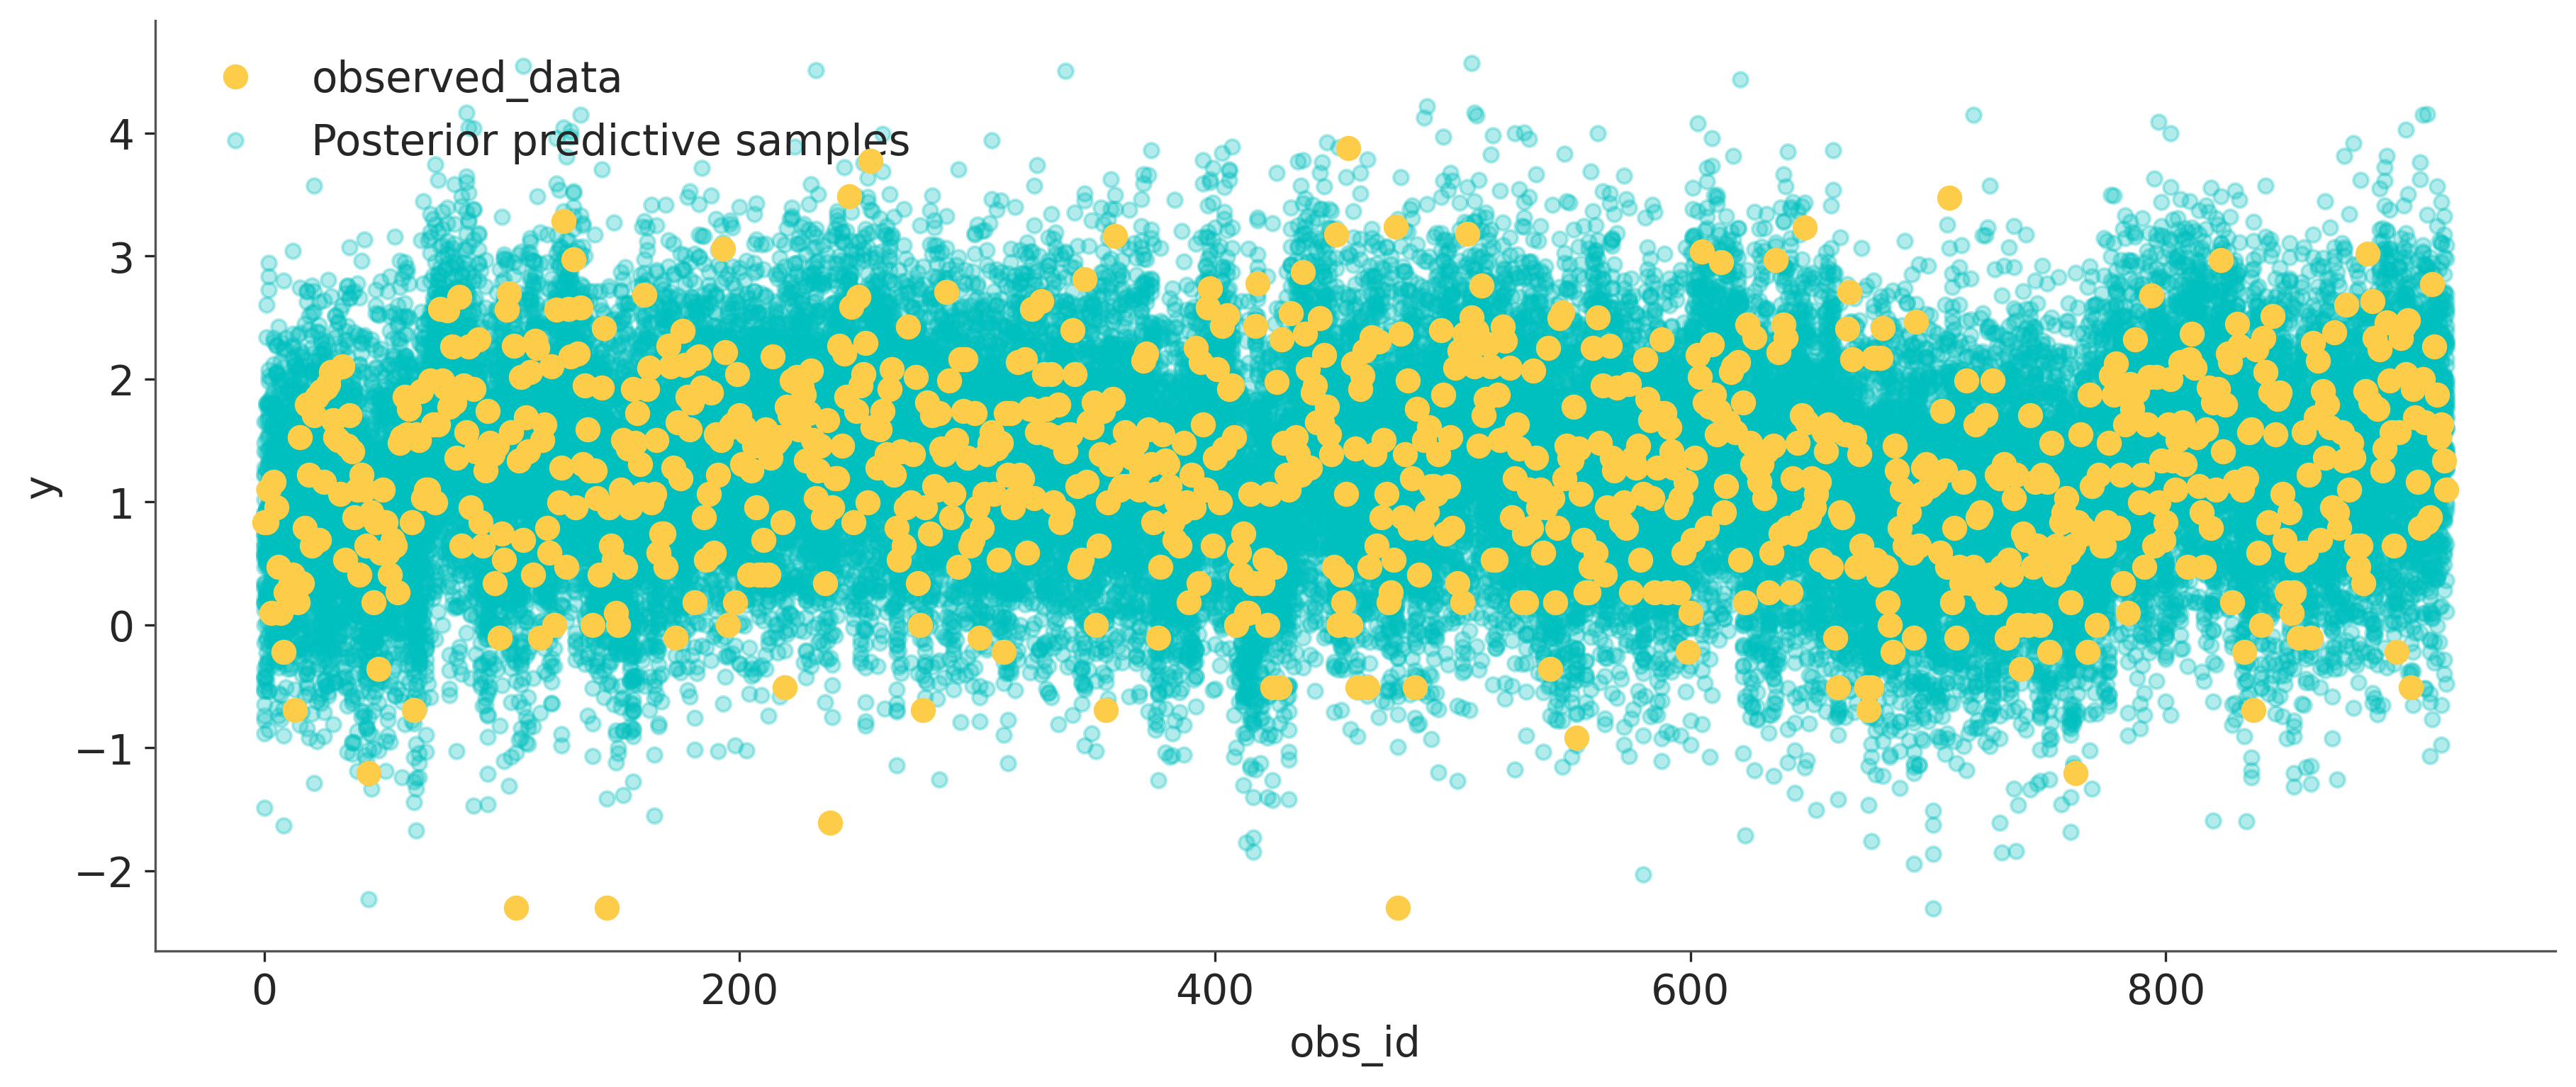

In [15]:
az.style.use("arviz-doc")
az.plot_lm(
    y=idata.observed_data["y"],
    x=idata.observed_data["obs_id"],
    y_hat=idata.posterior_predictive["y"],
    figsize=[12, 5],
    grid=False
);

In [30]:
idata.observed_data

<xarray.Dataset> Size: 15kB
Dimensions:  (obs_id: 919)
Coordinates:
  * obs_id   (obs_id) int64 7kB 0 1 2 3 4 5 6 7 ... 912 913 914 915 916 917 918
Data variables:
    y        (obs_id) float64 7kB 0.8329 0.8329 1.099 ... 1.629 1.335 1.099
Attributes:
    created_at:                 2020-07-24T18:15:12.458415
    arviz_version:              0.9.0
    inference_library:          pymc3
    inference_library_version:  3.9.2

In [44]:
import polars as pl

county_obs_ix = idata.constant_data["county_idx"].values
county_obs = idata.constant_data.coords["County"].values[county_obs_ix]
obs = pl.DataFrame({
    "county": county_obs,
    "floor": np.array(["basement", "first_floor"])[idata.constant_data["floor_idx"].values],
    "y": idata.observed_data["y"].values,
    "obs_id": idata.observed_data.coords["obs_id"].values
})
obs.head()

county,floor,y,obs_id
str,str,f64,i64
"""AITKIN""","""first_floor""",0.832909,0
"""AITKIN""","""basement""",0.832909,1
"""AITKIN""","""basement""",1.098612,2
"""AITKIN""","""basement""",0.09531,3
"""ANOKA""","""basement""",1.163151,4


In [57]:
qs = pl.DataFrame(
    idata.posterior_predictive["y"]
    .quantile([0.01, 0.99], dim=["chain", "draw"])
    .to_series()
    .unstack("quantile")
    .add_prefix("q")
    .reset_index()
)
df_plot = obs.join(qs, on="obs_id").sort("county")
df_plot.head()

county,floor,y,obs_id,q0.01,q0.99
str,str,f64,i64,f64,f64
"""AITKIN""","""first_floor""",0.832909,0,-1.48535,2.046636
"""AITKIN""","""basement""",0.832909,1,-0.805899,2.664927
"""AITKIN""","""basement""",1.098612,2,-0.759009,2.594002
"""AITKIN""","""basement""",0.09531,3,-0.737633,2.709278
"""ANOKA""","""basement""",1.163151,4,-0.78447,2.569806


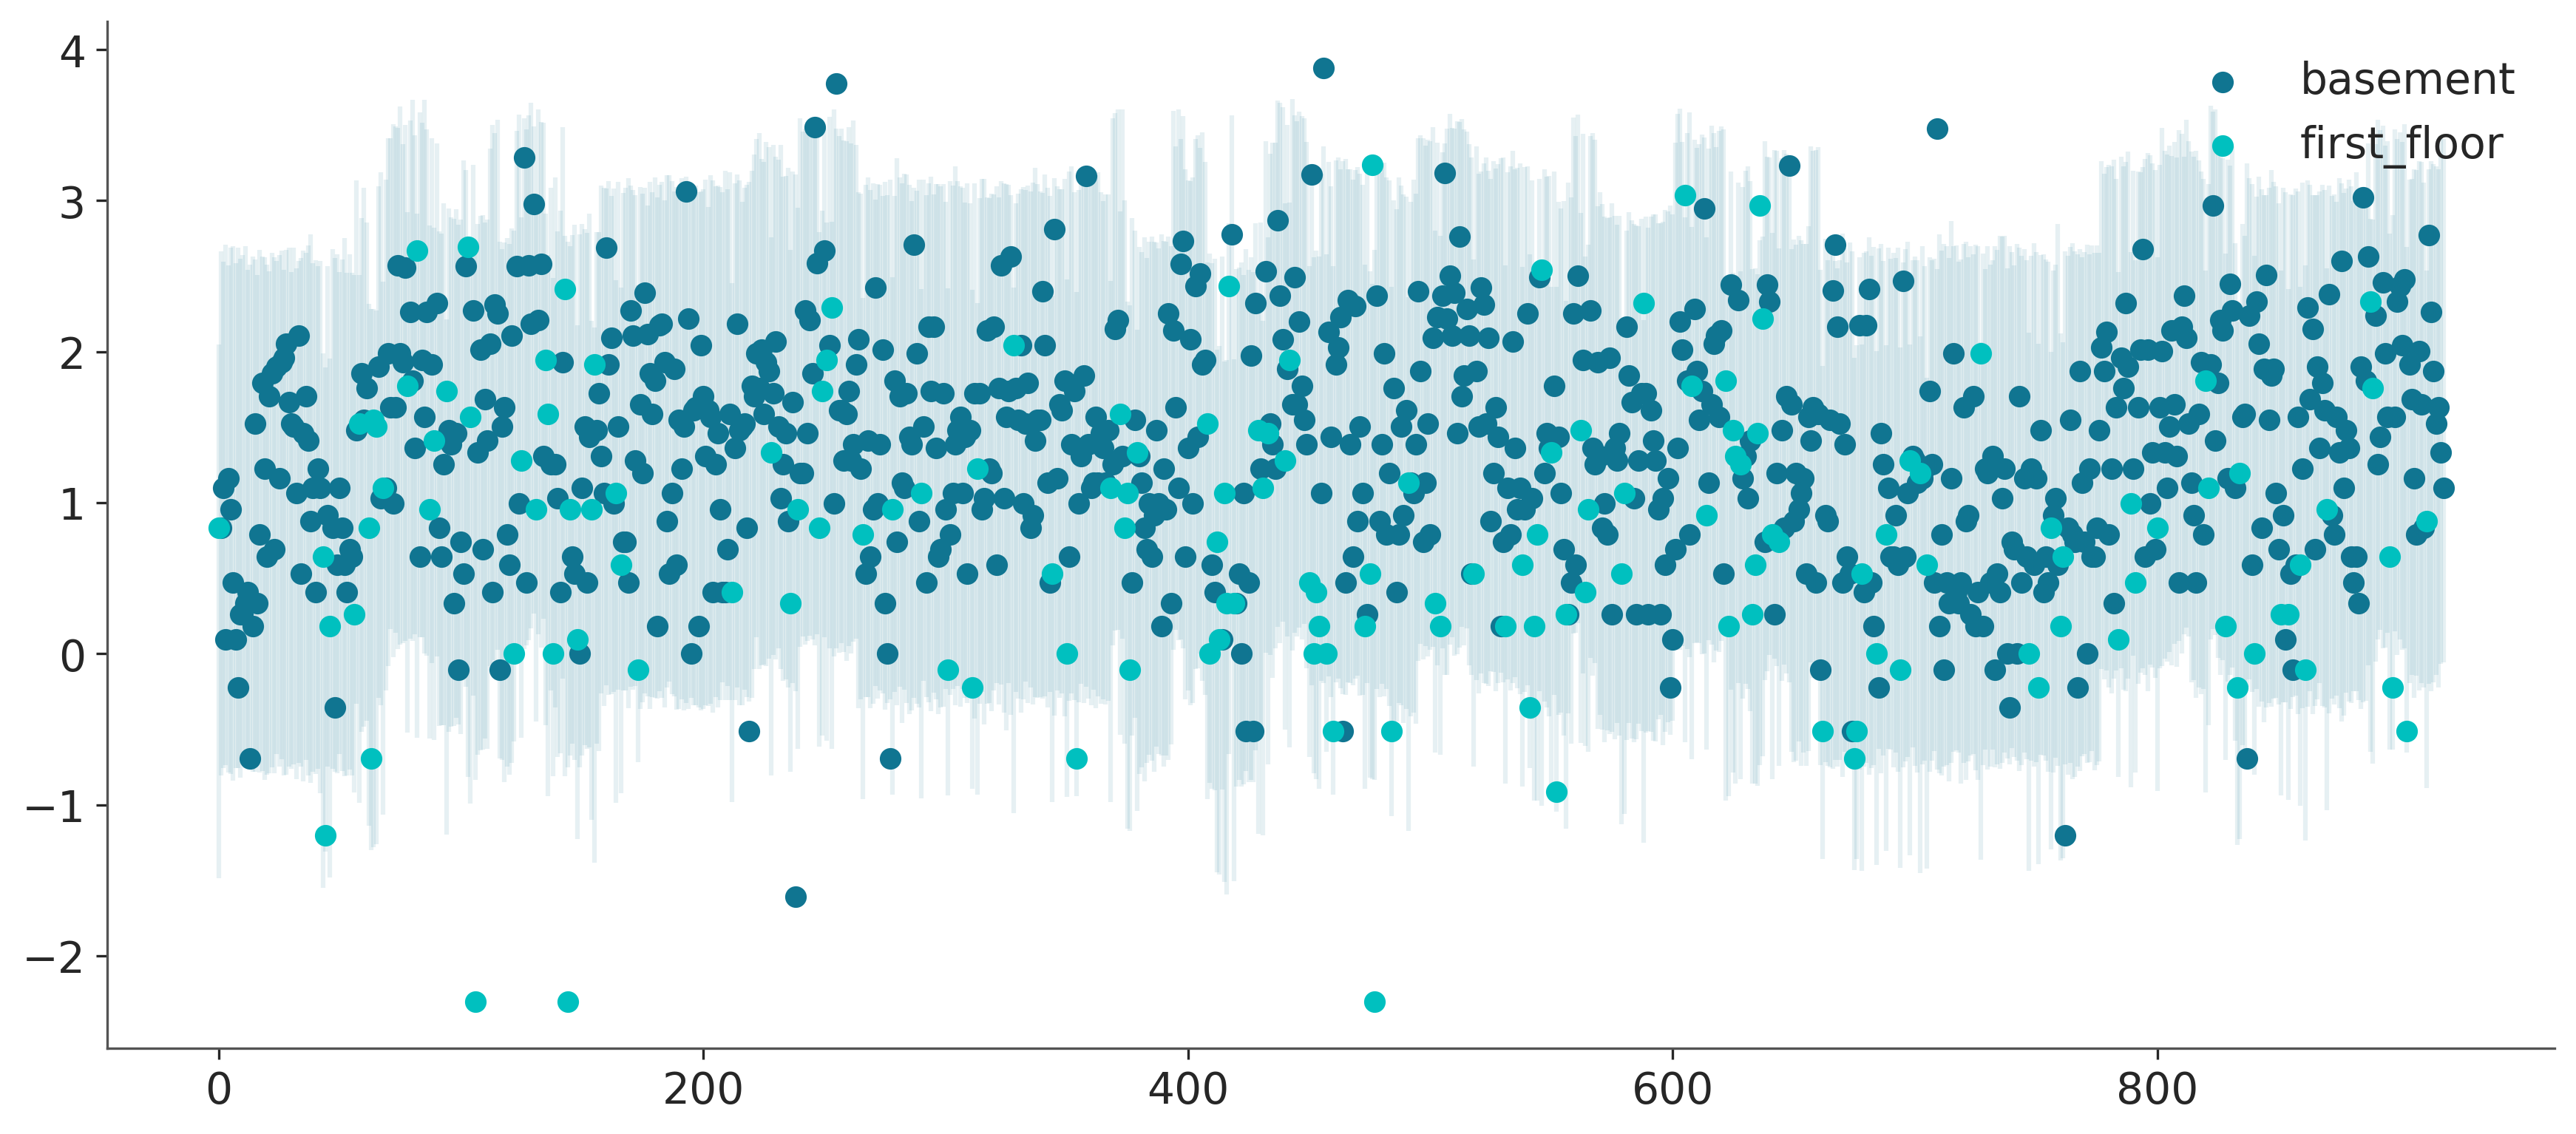

In [62]:
from matplotlib import pyplot as plt

f, ax = plt.subplots()
for (floor,), subdf in df_plot.group_by("floor"):
    ax.scatter(subdf["obs_id"], subdf["y"], label=floor);
    ax.vlines(
        subdf["obs_id"],
        subdf["q0.01"],
        subdf["q0.99"],
        zorder=-1,
        alpha=0.1,
        # color="gainsboro"
    )
ax.legend()

The function `az.loo` can quickly estimate a model’s out of sample log
likelihood (which we saw above is a nice default loss function),
allowing a nice numerical comparison between models.

Watch out for the `warning` column, which can tell you if the estimation
is likely to be incorrect. It’s usually a good idea to set the
`pointwise` argument to `True`, as this allows for more detailed
analysis at the per-observation level.

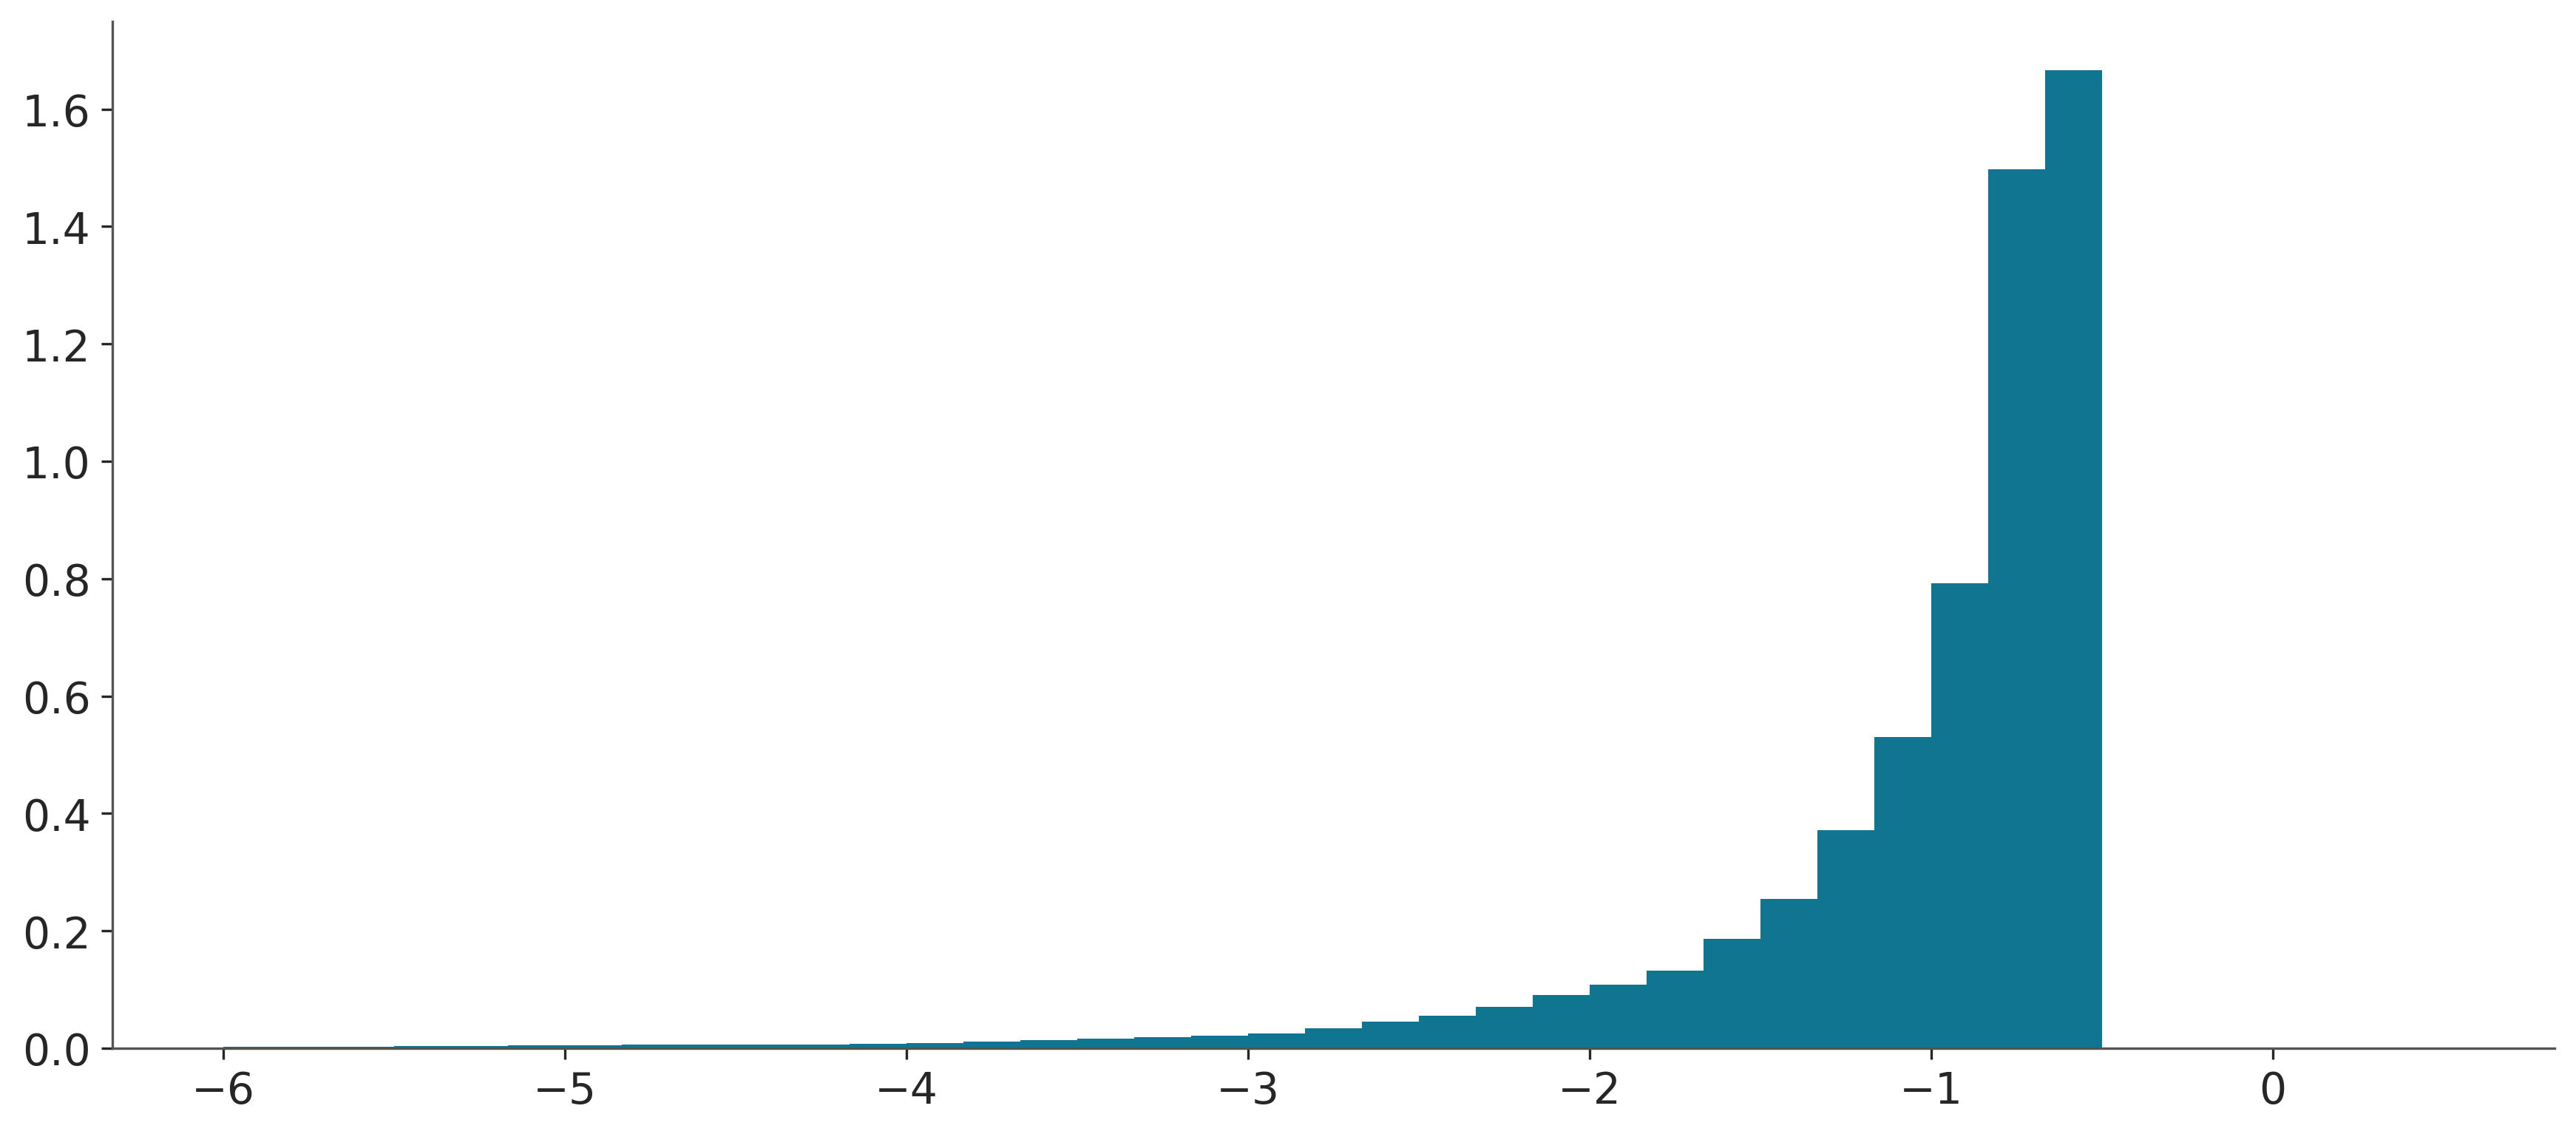

In [69]:
f, ax = plt.subplots()

ax.hist(idata.log_likelihood["y"].values.flatten(), bins=np.linspace(-6, 0.5, 40), density=True);

In [76]:
idata.log_likelihood["y"].sum(dim=["obs_id"]).mean().item()

-1013.3431460372753

In [81]:
loo = az.loo(idata, var_name="y", pointwise=True)

loo

Computed from 2000 posterior samples and 919 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -1027.18    28.85
p_loo       26.82        -
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)      919  100.0%
   (0.70, 1]   (bad)         0    0.0%
   (1, Inf)   (very bad)    0    0.0%

The function `az.compare` is useful for comparing different out of
sample log likelihood estimates.

In [6]:
idata.log_likelihood["fake"] = xr.DataArray(
    # generate some fake log likelihoods
    np.random.normal(0, 2, [4, 500, 919]),
    coords=idata.log_likelihood.coords,
    dims=idata.log_likelihood.dims
)
comparison = az.compare(
    {
        "real": az.loo(idata, var_name="y"), 
        "fake": az.loo(idata, var_name="fake")
    }
)
comparison

/Users/tedgro/repos/dtu-qmcm/bayesian_statistics_for_computational_biology/.venv/lib/python3.13/site-packages/arviz/stats/stats.py:797: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


,rank,elpd_loo,p_loo,elpd_diff,weight,se,dse,warning,scale
real,0,-1027.176982,26.817161,0.000000,0.984927,28.848998,0.000000,False,log
fake,1,-1795.671784,3618.232494,768.494803,0.015073,3.486204,28.965319,True,log


The function
[`az.plot_compare`](https://python.arviz.org/en/latest/api/generated/arviz.plot_compare.html)
shows these results on a nice graph:

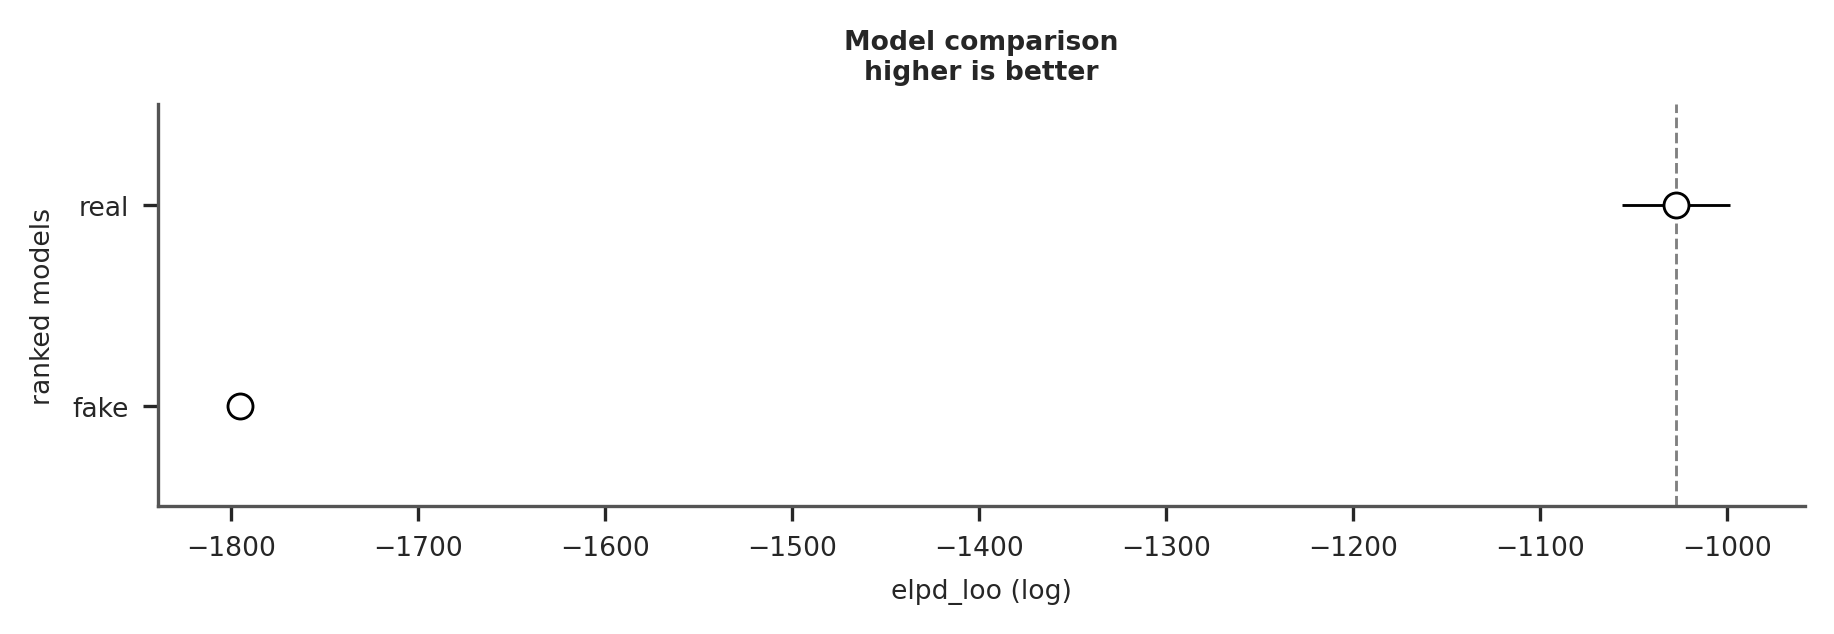

In [7]:
az.plot_compare(comparison);